```markdown
# Lab/Exp 8: Implementing Data Augmentation for Image Data

This notebook demonstrates how to load, augment, and train a Convolutional Neural Network (CNN) using PyTorch on the **Intel Image Classification Dataset**.

### Steps:
1. Kaggle dataset setup & download.
2. Apply data augmentation techniques using PyTorch `transforms`.
3. Create PyTorch `DataLoaders`.
4. Define a custom CNN architecture.
5. Train and evaluate the model.
6. Visualize the training performance (loss and accuracy).
```

```markdown
## Step 1: Download the Intel Image Dataset
To download the dataset from Kaggle, please upload your `kaggle.json` API key to the environment or insert your Kaggle credentials below.
```

In [1]:
import os
from google.colab import files

# Check if kaggle.json is present, if not prompt to upload
if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Please upload your kaggle.json API key token:")
    uploaded = files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    for fn in uploaded.keys():
        os.rename(fn, '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)

# Download and unzip the Intel Image Classification dataset
!kaggle datasets download -d puneet6060/intel-image-classification
!unzip -q intel-image-classification.zip -d intel_images
print("Dataset downloaded and extracted successfully!")

Please upload your kaggle.json API key token:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:19<00:00, 18.6MB/s]

Dataset downloaded and extracted successfully!


```markdown
## Step 2: Set Up Data Augmentation & Datasets
We will define two separate transformation pipelines: one with heavy augmentation for the training set, and one basic normalization pipeline for the validation/test set.
```

In [2]:
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Image Dimensions
IMG_SIZE = 150
BATCH_SIZE = 64

# Define data augmentation for training
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Define simple transformation for testing (no augmentation)
test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Paths to data
train_dir = 'intel_images/seg_train/seg_train'
test_dir = 'intel_images/seg_test/seg_test'

# Create Datasets
train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transforms)
test_dataset = datasets.ImageFolder(root=test_dir, transform=test_transforms)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

class_names = train_dataset.classes
print(f"Classes: {class_names}")
print(f"Training images: {len(train_dataset)}, Testing images: {len(test_dataset)}")

Using device: cuda
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Training images: 14034, Testing images: 3000


```markdown
## Step 3: Visualize Augmented Images
Let's plot a few images from the augmented training set to verify the transforms.
```

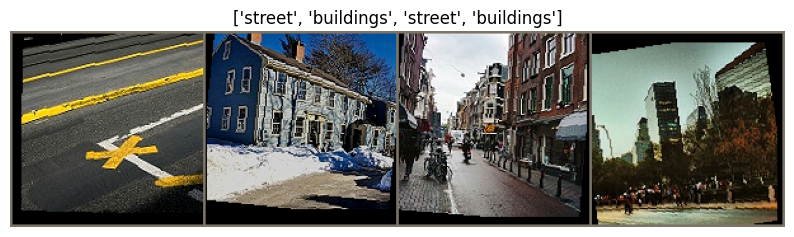

In [3]:
def imshow(img, title=None):
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    if title is not None:
        plt.title(title)
    plt.axis('off')

# Grab a batch
images, labels = next(iter(train_loader))
out = torchvision.utils.make_grid(images[:4])

plt.figure(figsize=(10, 5))
imshow(out, title=[class_names[x] for x in labels[:4]])
plt.show()

```markdown
## Step 4: Define the PyTorch CNN Architecture
```

In [4]:
import torch.nn as nn
import torch.nn.functional as F

class IntelCNN(nn.Module):
    def __init__(self, num_classes=6):
        super(IntelCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.4)

        # Output spatial size after 3 maxpools: 150 / 8 = 18.75 -> approx 18x18
        # Let's use AdaptiveAvgPool2d to guarantee size before FC
        self.adaptive_pool = nn.AdaptiveAvgPool2d((7, 7))

        self.fc1 = nn.Linear(128 * 7 * 7, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.adaptive_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

model = IntelCNN(num_classes=len(class_names)).to(device)
print(model)

IntelCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.4, inplace=False)
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(7, 7))
  (fc1): Linear(in_features=6272, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=6, bias=True)
)


```markdown
## Step 5: Training Loop
We will define the loss function, optimizer, and write code to train our network over 10 epochs while recording performance.
```

In [5]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (correct / total) * 100
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)

    # Evaluation
    model.eval()
    test_loss = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            test_total += labels.size(0)
            test_correct += predicted.eq(labels).sum().item()

    epoch_test_loss = test_loss / len(test_loader.dataset)
    epoch_test_acc = (test_correct / test_total) * 100
    test_losses.append(epoch_test_loss)
    test_accs.append(epoch_test_acc)

    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_loss:.4f} - Train Acc: {epoch_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} - Test Acc: {epoch_test_acc:.2f}%")

Epoch [1/10] | Train Loss: 1.1639 - Train Acc: 57.61% | Test Loss: 0.7162 - Test Acc: 73.10%
Epoch [2/10] | Train Loss: 0.7914 - Train Acc: 70.32% | Test Loss: 0.7778 - Test Acc: 72.43%
Epoch [3/10] | Train Loss: 0.7003 - Train Acc: 74.21% | Test Loss: 0.5905 - Test Acc: 79.17%
Epoch [4/10] | Train Loss: 0.6581 - Train Acc: 76.11% | Test Loss: 0.5273 - Test Acc: 81.97%
Epoch [5/10] | Train Loss: 0.6168 - Train Acc: 77.86% | Test Loss: 0.5441 - Test Acc: 82.27%
Epoch [6/10] | Train Loss: 0.6033 - Train Acc: 78.22% | Test Loss: 0.4759 - Test Acc: 83.40%
Epoch [7/10] | Train Loss: 0.5758 - Train Acc: 79.09% | Test Loss: 0.4840 - Test Acc: 83.83%
Epoch [8/10] | Train Loss: 0.5552 - Train Acc: 79.92% | Test Loss: 0.6397 - Test Acc: 77.73%
Epoch [9/10] | Train Loss: 0.5416 - Train Acc: 80.58% | Test Loss: 0.4556 - Test Acc: 84.90%
Epoch [10/10] | Train Loss: 0.5158 - Train Acc: 81.48% | Test Loss: 0.4391 - Test Acc: 84.87%


```markdown
## Step 6: Plot Performance Curves
```

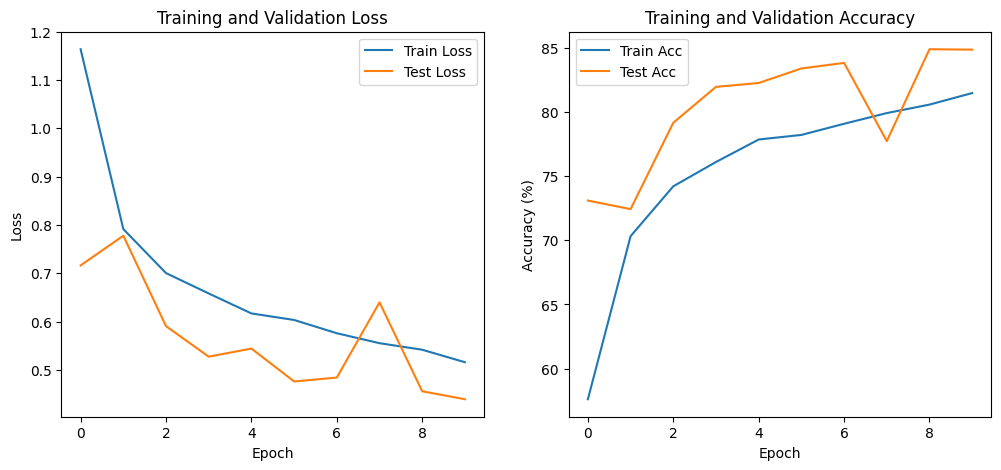

In [6]:
plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(test_accs, label='Test Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.title('Training and Validation Accuracy')

plt.show()

```markdown
## Step 7: Confusion Matrix
Let's generate predictions for the entire test set and visualize the confusion matrix to understand where the model is making errors.
```

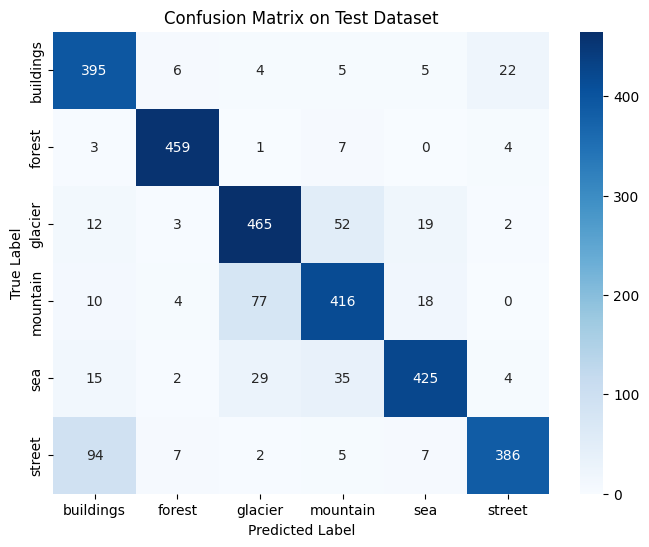

In [7]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Test Dataset')
plt.show()